# LFP proxy and spatial spike snapshots

This notebook generates spatial snapshots of the **LFP proxy and excitatory/inhibitory spiking activity**, as shown in Fig. 4d–e. LFP maps are displayed at user-defined time intervals (BIN_MS), together with the spatial locations of neurons that fired within each corresponding time bin.

**Usage:** Select which condition to plot by setting `SELECTED_RUNS = ['condition_1']` (Fig4d) or `SELECTED_RUNS = ['condition_2']` (Fig4e),  and specify the time window using `START_MS`, `BIN_MS`, and `N_FRAMES`. The corresponding LFP, spike, and geometry `.mat` files must be present in the specified folders. Run all cells to generate and save the figures.

Each condition has two rows: LFP maps at the **right endpoints** of successive time bins, and locations of neurons that spiked during those bins. Excitatory neurons are blue; inhibitory neurons are red. The same recorded neurons are used throughout.

**Run locally:** install `numpy scipy matplotlib` (and `h5py` only for MATLAB v7.3 files), perform the small simulation edits below, set `RUNS` and the plotting parameters, then run the Python cells. Brian2 is needed only for the simulation, not this notebook.

The supplied simulation monitors the **first 40,000 E and 10,000 I neurons**, whose positions were drawn uniformly at random. It does not explicitly draw random neuron IDs. This notebook uses that recorded set of 50,000; it never generates replacement neuron positions or spikes. The original script does not save neuron positions, so a geometry export from the matching run is required. Already-finished runs without saved positions cannot be spatially plotted from the spike and LFP files alone.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.io import loadmat
from scipy import signal


# Select the run to plot: condition_1 or condition_2
SELECTED_RUNS = ['condition_1']

# Available runs
RUN_CATALOG = {
    'condition_1': dict(
        folder=Path('.'), trial=2, ext_field=1, iteration=1,
        label='Condition 1', spike_naming='tagged'
    ),
    'condition_2': dict(
        folder=Path('.'), trial=1, ext_field=2, iteration=1,
        label='Condition 2', spike_naming='tagged'
    ),
}
 

RUNS = [RUN_CATALOG[name] for name in SELECTED_RUNS]
START_MS = 660.0             # relative to start of the selected iteration
BIN_MS = 3.0                 # spikes in (left edge, right edge]
N_FRAMES = 12
# Override per condition with start_ms=... in its RUNS entry if needed.

LFP_MODE = 'demean'          # 'demean', 'bandpass', or 'raw'
BAND_HZ = (10.0, 30.0)       # used only for LFP_MODE='bandpass'; explicit band
FILTER_ORDER = 4
NORMALIZE_LFP = True         # shared maximum |LFP| across ALL displayed frames/runs
LFP_INTERPOLATION = 'bilinear'  # 'nearest' shows original electrode pixels
VIEW = 'array'              # 'array': electrode pixel footprint; 'sheet': whole sheet
# Both rows always have identical physical limits. Array view crops the spike map.
# Sheet view leaves blank space outside the measured LFP array, with no extrapolation.

E_COLOR = '#174A8B'
I_COLOR = '#D62828'
DOT_SIZE = 1.5               # scatter area, points squared
OUTPUT_DIR = Path('snapshot_figures')
OUTPUT_STEM = 'lfp_and_spike_snapshots'
SAVE_FORMATS = ('svg', 'png')
DPI = 300
plt.rcParams.update({'figure.dpi': 120, 'svg.fonttype': 'none'})

## 2. Load and validate the saved arrays

The LFP variable is `data` with shape time × recording sites, sampled every 1 ms. It is the saved spatially weighted `|I_AMPA| + |I_GABA|` proxy. Channel positions come from the geometry export; the map is assembled by physical x/y coordinates, preserving the simulation's channel ordering without a guessed transpose or vertical flip.

By default, subtract each channel's mean over the **whole selected iteration**. This removes the positive DC baseline and permits a red/blue fluctuation map. Optional bandpass filtering also operates on the whole iteration before snapshots are taken. There is no automatic wave selection: choose the time window explicitly. A single color scale is used across all conditions and snapshots; normalization never occurs independently per panel or condition.

In [2]:
def read_mat(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path.resolve()}')
    try:
        return {k: np.asarray(v) for k, v in loadmat(path).items()
                if not k.startswith('__')}
    except NotImplementedError:
        try:
            import h5py
        except ImportError as exc:
            raise ImportError('Install h5py to read MATLAB v7.3 files.') from exc
        with h5py.File(path, 'r') as f:
            return {k: np.asarray(v).T for k, v in f.items()
                    if isinstance(v, h5py.Dataset)}


def scalar(data, key):
    a = np.asarray(data[key]).ravel()
    if a.size != 1 or not np.isfinite(a[0]):
        raise ValueError(f'{key} must be one finite scalar.')
    return float(a[0])


def int_ids(a, name):
    a = np.asarray(a).ravel()
    if not np.all(np.isfinite(a)) or np.any(a != np.floor(a)) or np.any(a < 0):
        raise ValueError(f'{name}: expected nonnegative integer neuron IDs.')
    return a.astype(np.int64)


def pixel_edges(centers):
    if len(centers) < 2 or not np.allclose(np.diff(centers), np.diff(centers)[0]):
        raise ValueError('Expected a regular electrode grid with at least two sites per axis.')
    half_step = np.diff(centers)[0] / 2
    return centers[0] - half_step, centers[-1] + half_step


def load_run(spec):
    folder = Path(spec['folder']).expanduser()
    trial, cond, iteration = (int(spec[k]) for k in ('trial', 'ext_field', 'iteration'))
    if iteration < 1:
        raise ValueError('iteration uses the LFP convention: 1, 2, ...')
    tag = f'i{iteration}_J{cond}_trial{trial}'
    geometry_path = folder / f'snapshot_geometry_J{cond}_trial{trial}.mat'
    if not geometry_path.is_file():
        raise FileNotFoundError(f'{geometry_path}: add the geometry export from section 1 '
                                'to the matching simulation; neuron positions are required.')
    geo = read_mat(geometry_path)
    if scalar(geo, 'trial') != trial or scalar(geo, 'ext_field') != cond:
        raise ValueError('Geometry metadata does not match the requested run.')
    dt = scalar(geo, 'lfp_dt_ms')
    duration = scalar(geo, 'duration_ms')
    warmup = scalar(geo, 'warmup_ms')
    if dt <= 0 or duration <= 0 or warmup < 0:
        raise ValueError('Invalid time metadata.')
    absolute_start = warmup + (iteration - 1) * duration
    rx, ry = (np.asarray(geo[k], float).ravel() for k in ('rec_x_um', 'rec_y_um'))
    if len(rx) != len(ry) or not np.all(np.isfinite(np.r_[rx, ry])):
        raise ValueError('Invalid recording-site coordinates.')
    xs, ys = np.unique(rx), np.unique(ry)
    xi, yi = np.searchsorted(xs, rx), np.searchsorted(ys, ry)
    if len(rx) != len(xs) * len(ys) or len(np.unique(yi * len(xs) + xi)) != len(rx):
        raise ValueError('Recording sites must form a complete rectangular grid.')
    array_extent = (*pixel_edges(xs), *pixel_edges(ys))
    lfp = np.asarray(read_mat(folder / f'LFP_{tag}.mat')['data'], float)
    if lfp.ndim != 2 or lfp.shape[1] != len(rx):
        raise ValueError(f'LFP shape {lfp.shape}; expected time × {len(rx)} sites.')
    if not np.all(np.isfinite(lfp)) or not np.isclose(len(lfp) * dt, duration):
        raise ValueError('LFP contains nonfinite values or its length disagrees with duration_ms.')
    if LFP_MODE == 'demean':
        lfp = lfp - lfp.mean(axis=0)
    elif LFP_MODE == 'bandpass':
        if not 0 < BAND_HZ[0] < BAND_HZ[1] < 500 / dt:
            raise ValueError('BAND_HZ must lie between 0 and the Nyquist frequency.')
        sos = signal.butter(FILTER_ORDER, BAND_HZ, btype='bandpass', fs=1000 / dt, output='sos')
        lfp = signal.sosfiltfilt(sos, lfp - lfp.mean(axis=0), axis=0)
    elif LFP_MODE != 'raw':
        raise ValueError('Unknown LFP_MODE.')
    start = float(spec.get('start_ms', START_MS))
    edges = start + np.arange(N_FRAMES + 1) * BIN_MS
    if start < 0 or edges[-1] > (len(lfp) - 1) * dt:
        raise ValueError(f'{tag}: requested times {edges[0]:g}–{edges[-1]:g} ms '
                         f'exceed available LFP times 0–{(len(lfp)-1)*dt:g} ms.')
    sample_idx = np.rint(edges[1:] / dt).astype(int)
    if not np.allclose(sample_idx * dt, edges[1:], atol=1e-8, rtol=0):
        raise ValueError('Choose START_MS and BIN_MS so all endpoints land on LFP sample times.')
    maps = np.empty((N_FRAMES, len(ys), len(xs)))
    maps[:, yi, xi] = lfp[sample_idx]
    extent = array_extent if VIEW == 'array' else (
        -scalar(geo, 'size_x_um') / 2, scalar(geo, 'size_x_um') / 2,
        -scalar(geo, 'size_y_um') / 2, scalar(geo, 'size_y_um') / 2)
    naming = spec.get('spike_naming', 'tagged')
    if naming == 'legacy':
        spike_tag = f'i{iteration-1}_J{int(spec.get("legacy_J", 1))}'
        warnings.warn(f'{folder}: legacy spike names do not identify condition/trial. '
                      'Verify they belong to this run and were not overwritten.', stacklevel=2)
    elif naming == 'tagged':
        spike_tag = tag
    else:
        raise ValueError("spike_naming must be 'tagged' or 'legacy'.")
    spikes, counts = {}, {}
    for pop in ('E', 'I'):
        ids = int_ids(geo[f'{pop}_ids'], f'{pop} geometry')
        x, y = (np.asarray(geo[f'{pop}_{axis}_um'], float).ravel() for axis in ('x', 'y'))
        if len(ids) != len(x) or len(ids) != len(y) or len(np.unique(ids)) != len(ids):
            raise ValueError(f'{pop}: inconsistent geometry lengths or duplicate IDs.')
        if not np.all(np.isfinite(np.r_[x, y])):
            raise ValueError(f'{pop}: nonfinite neuron positions.')
        counts[pop] = len(ids)
        times = np.asarray(read_mat(folder / f'{pop}_spike_times_{spike_tag}.mat')['SpikeTimes'], float).ravel() * 1000
        event_ids = int_ids(read_mat(folder / f'{pop}_spike_id_{spike_tag}.mat')['SpikeId'], f'{pop} spikes')
        if len(times) != len(event_ids) or not np.all(np.isfinite(times)):
            raise ValueError(f'{pop}: invalid spike arrays.')
        if np.any(times < absolute_start - 1e-6) or np.any(times >= absolute_start + duration + 1e-6):
            raise ValueError(f'{pop}: spike timestamps disagree with iteration/warmup metadata.')
        if not np.all(np.isin(event_ids, ids)):
            raise ValueError(f'{pop}: spike IDs missing from geometry (wrong run or ID convention).')
        order = np.argsort(ids)
        sorted_ids = ids[order]
        relative_times = times - absolute_start
        snapshots = []
        for left, right in zip(edges[:-1], edges[1:]):
            # Right-closed disjoint bins. Tiny tolerance handles saved floating-point times.
            active = np.unique(event_ids[(relative_times > left + 1e-8) &
                                         (relative_times <= right + 1e-8)])
            loc = order[np.searchsorted(sorted_ids, active)]
            snapshots.append(np.column_stack((x[loc], y[loc])))
        spikes[pop] = snapshots
    print(f'{spec["label"]}: {counts["E"]:,} E + {counts["I"]:,} I recorded neurons; '
          f'absolute simulation window {absolute_start+edges[0]:g}–{absolute_start+edges[-1]:g} ms; '
          f'grid {len(xs)} × {len(ys)}.')
    if sum(counts.values()) != 50000:
        warnings.warn('This geometry contains a different number of recorded neurons than 50,000.')
    return dict(spec=spec, maps=maps, spikes=spikes, edges=edges, extent=extent,
                array_extent=array_extent, absolute_start=absolute_start, counts=counts)


if not RUNS or N_FRAMES < 1 or int(N_FRAMES) != N_FRAMES or BIN_MS <= 0:
    raise ValueError('Choose at least one run, a positive integer N_FRAMES and BIN_MS > 0.')
if VIEW not in ('array', 'sheet'):
    raise ValueError("VIEW must be 'array' or 'sheet'.")
loaded = [load_run(spec) for spec in RUNS]

Condition 1: 40,000 E + 10,000 I recorded neurons; absolute simulation window 860–896 ms; grid 12 × 12.


## 3. Plot and save

Titles reset time to zero at the start of each displayed window. The printed summary gives the corresponding absolute simulation times. Each dot represents one recorded neuron that fired at least once in that bin. Repeated spikes from the same neuron would occupy the same location and are plotted once.

`VIEW='array'` shows the electrode pixel footprint in both rows, so recorded neurons outside that footprint are not visible. Use `VIEW='sheet'` to display the full 50,000-neuron recording domain, with an unfilled border around the smaller LFP array. `bilinear` only interpolates the image for display; it does not add measured sites.

SVG output keeps text and spike markers as vectors; the LFP images are embedded raster images. PNG is saved at the specified DPI. The figure is produced from the saved data only.

Saved: /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub_clean/simulations/results_f4/Print_waves_spikes/snapshot_figures/lfp_and_spike_snapshots.svg
Saved: /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub_clean/simulations/results_f4/Print_waves_spikes/snapshot_figures/lfp_and_spike_snapshots.png


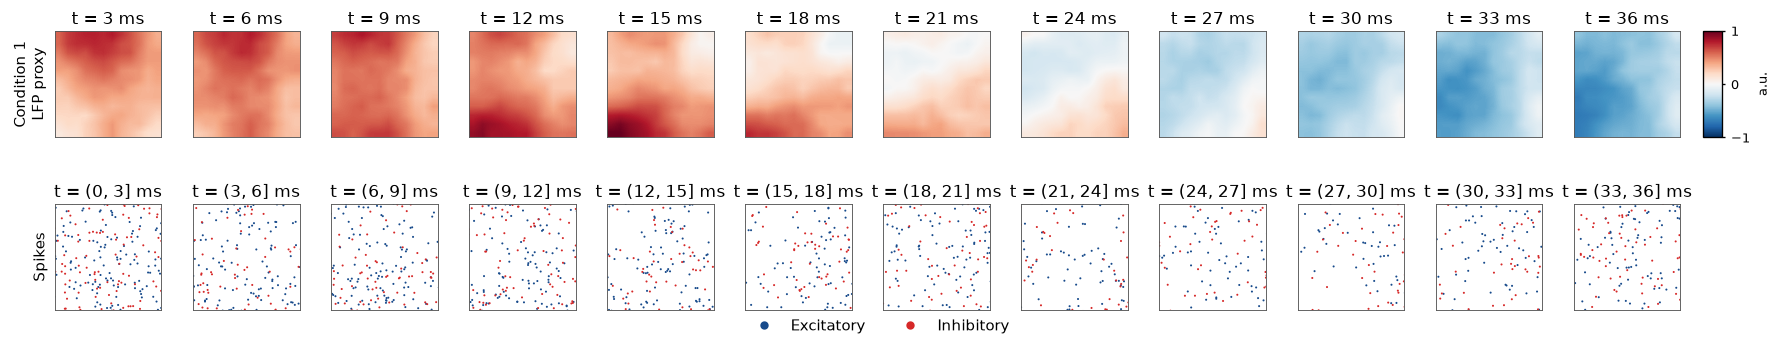

In [3]:
shared_max = max(float(np.max(np.abs(run['maps']))) for run in loaded)
if shared_max == 0:
    shared_max = 1.0
scale = shared_max if NORMALIZE_LFP else 1.0
vmax = 1.0 if NORMALIZE_LFP else shared_max
nrows = 2 * len(loaded)
fig = plt.figure(figsize=(1.23 * N_FRAMES + 1.2, 2.95 * len(loaded)))
gs = fig.add_gridspec(nrows, N_FRAMES + 1, width_ratios=[1] * N_FRAMES + [0.15],
                      left=0.065, right=0.94, bottom=0.12, top=0.91,
                      hspace=0.62, wspace=0.12)
all_axes = []
for r, run in enumerate(loaded):
    for j in range(N_FRAMES):
        top = fig.add_subplot(gs[2*r, j])
        bottom = fig.add_subplot(gs[2*r+1, j])
        im = top.imshow(run['maps'][j] / scale, origin='lower',
                        extent=run['array_extent'], interpolation=LFP_INTERPOLATION,
                        cmap='RdBu_r', vmin=-vmax, vmax=vmax)
        for pop, color in [('E', E_COLOR), ('I', I_COLOR)]:
            xy = run['spikes'][pop][j]
            bottom.scatter(xy[:, 0], xy[:, 1], s=DOT_SIZE, c=color,
                           edgecolors='none', linewidths=0)
        left, right = run['edges'][j:j+2] - run['edges'][0]
        top.set_title(f't = {right:g} ms', fontsize=10, pad=4)
        bottom.set_title(f't = ({left:g}, {right:g}] ms', fontsize=10, pad=4)
        for ax in (top, bottom):
            ax.set_xlim(run['extent'][:2]); ax.set_ylim(run['extent'][2:])
            ax.set_aspect('equal', adjustable='box')
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_linewidth(0.55); spine.set_color('0.35')
        if j == 0:
            top.set_ylabel(f'{run["spec"]["label"]}\nLFP proxy', fontsize=9)
            bottom.set_ylabel('Spikes', fontsize=9)
        all_axes.extend((top, bottom))
    cax = fig.add_subplot(gs[2*r, -1])
    cb = fig.colorbar(im, cax=cax, ticks=[-vmax, 0, vmax])
    cb.ax.tick_params(labelsize=8, length=2)
    cb.set_label('a.u.' if NORMALIZE_LFP else 'saved proxy units', fontsize=8)
    fig.add_subplot(gs[2*r+1, -1]).set_axis_off()
legend_handles = [Line2D([], [], marker='o', linestyle='', color=c, markersize=4, label=p)
                  for p, c in [('Excitatory', E_COLOR), ('Inhibitory', I_COLOR)]]
fig.legend(handles=legend_handles, loc='lower center', ncol=2, frameon=False,
           fontsize=9, bbox_to_anchor=(0.5, 0.015))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for extension in SAVE_FORMATS:
    target = OUTPUT_DIR / f'{OUTPUT_STEM}.{extension}'
    fig.savefig(target, dpi=DPI, bbox_inches='tight', facecolor='white')
    print('Saved:', target.resolve())
plt.show()

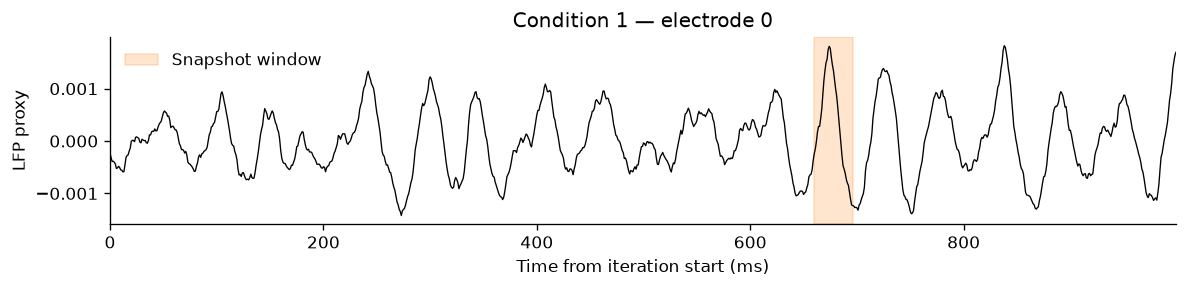

In [4]:
CHANNEL = 0  # zero-based electrode index

fig, axes = plt.subplots(
    len(loaded), 1,
    figsize=(10, 2.5 * len(loaded)),
    squeeze=False,
)

for ax, run in zip(axes[:, 0], loaded):
    spec = run["spec"]
    folder = Path(spec["folder"]).expanduser()
    tag = (
        f'i{spec["iteration"]}_J{spec["ext_field"]}'
        f'_trial{spec["trial"]}'
    )

    data = np.asarray(
        read_mat(folder / f"LFP_{tag}.mat")["data"], float
    )
    geometry = read_mat(
        folder
        / f'snapshot_geometry_J{spec["ext_field"]}_trial{spec["trial"]}.mat'
    )
    dt_ms = scalar(geometry, "lfp_dt_ms")

    # Apply the same preprocessing as the spatial snapshots.
    if LFP_MODE == "demean":
        data = data - data.mean(axis=0)
    elif LFP_MODE == "bandpass":
        sos = signal.butter(
            FILTER_ORDER, BAND_HZ,
            btype="bandpass",
            fs=1000 / dt_ms,
            output="sos",
        )
        data = signal.sosfiltfilt(
            sos, data - data.mean(axis=0), axis=0
        )

    if not 0 <= CHANNEL < data.shape[1]:
        raise ValueError(f"CHANNEL must be between 0 and {data.shape[1] - 1}.")

    time_ms = np.arange(len(data)) * dt_ms
    ax.plot(time_ms, data[:, CHANNEL], color="black", linewidth=0.8)
    ax.axvspan(
        run["edges"][0], run["edges"][-1],
        color="tab:orange", alpha=0.2,
        label="Snapshot window",
    )

    ax.set_title(f'{spec["label"]} — electrode {CHANNEL}')
    ax.set_xlabel("Time from iteration start (ms)")
    ax.set_ylabel("LFP proxy")
    ax.set_xlim(time_ms[0], time_ms[-1])
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)

fig.tight_layout()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for extension in SAVE_FORMATS:
    fig.savefig(
        OUTPUT_DIR / f"{OUTPUT_STEM}_trace.{extension}",
        dpi=DPI, bbox_inches="tight",
    )

plt.show()